In [1]:
# load dependencies
import numpy as np
import pandas as pd
import skgstat as skg
import xarray as xr
from sklearn.preprocessing import QuantileTransformer
from skgstat import models
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.colors import LightSource
import gstatsim as gs
import random

In [2]:
# import data
ds = xr.open_dataset('Data/BedMachineAntarctica-v3.nc')

In [3]:
# set coordinates (in polar stereographic units)
xmin = -1227_250
xmax = -1058_250
ymin = -702_250
ymax = -579_250

x_slice = slice(xmin, xmax) if ds.x[0] < ds.x[-1] else slice(xmax, xmin)
y_slice = slice(ymin, ymax) if ds.y[0] < ds.y[-1] else slice(ymax, ymin)
test_area1 = ds.sel(x=x_slice, y=y_slice)
test_area1

<xarray.Dataset> Size: 2MB
Dimensions:    (y: 246, x: 338)
Coordinates:
  * y          (y) int32 984B -579500 -580000 -580500 ... -701500 -702000
  * x          (x) int32 1kB -1227000 -1226500 -1226000 ... -1059000 -1058500
Data variables:
    mapping    |S1 1B ...
    mask       (y, x) int8 83kB ...
    firn       (y, x) float32 333kB ...
    surface    (y, x) float32 333kB ...
    thickness  (y, x) float32 333kB ...
    bed        (y, x) float32 333kB ...
    errbed     (y, x) float32 333kB ...
    source     (y, x) int8 83kB ...
    dataid     (y, x) int8 83kB ...
    geoid      (y, x) int16 166kB ...
Attributes: (12/17)
    Conventions:                 CF-1.7
    Title:                       BedMachine Antarctica
    Author:                      Mathieu Morlighem
    version:                     03-Jun-2022 (v3.4)
    nx:                          13333.0
    ny:                          13333.0
    ...                          ...
    ymax:                        3333000
    spacing:                     500
    no_data:                     -9999.0
    license:                     No restrictions on access or use
    Data_citation:               Morlighem M. et al., (2019), Deep glacial tr...
    Notes:                       Data processed at the Department of Earth Sy...

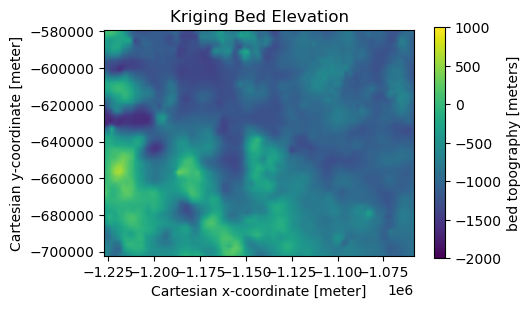

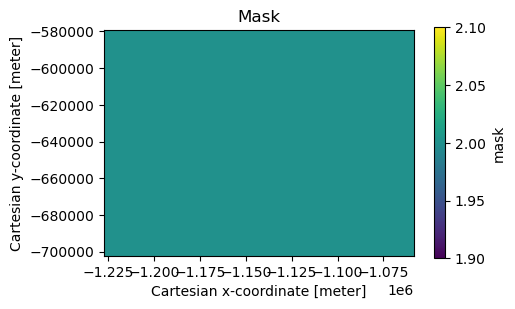

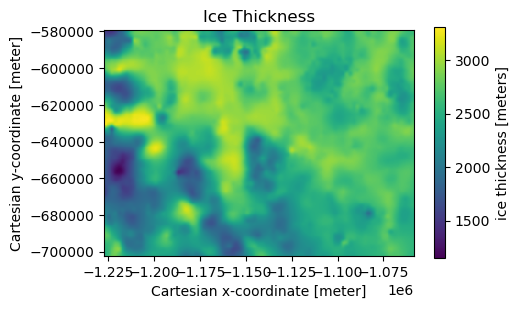

In [4]:
#initial Pots from Bedmachine3

#Plot bed elevation
fig, ax = plt.subplots(figsize=(5, 3))
test_area1["bed"].plot(ax=ax, x="x", y="y", cmap="viridis", add_colorbar=True, vmin = -2000, vmax = 1000)
ax.set_title("Kriging Bed Elevation")
ax.set_aspect("equal")
plt.show()

#Plot Mask
fig, ax = plt.subplots(figsize=(5, 3))
test_area1["mask"].plot(ax=ax, x="x", y="y", cmap="viridis", add_colorbar=True,)
ax.set_title("Mask")
ax.set_aspect("equal")
plt.show()

#Plot Ice Thickness
fig, ax = plt.subplots(figsize=(5, 3))
test_area1["thickness"].plot(ax=ax, x="x", y="y", cmap="viridis", add_colorbar=True)
ax.set_title("Ice Thickness")
ax.set_aspect("equal")
plt.show()

(-1227500.0, -1058500.0, -702500.0, -579500.0)

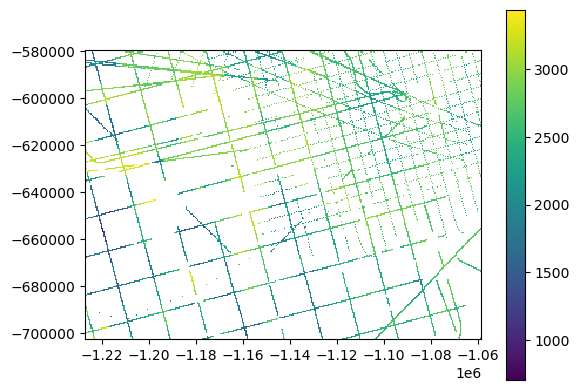

In [5]:
xmin_ant = -3333250
xmax_ant = 3333250
ymin_ant = -3333250
ymax_ant = 3333250

resolution = 500
xx_ant, yy_ant = np.meshgrid(np.arange(xmin_ant, xmax_ant + resolution, resolution), 
                     np.arange(ymin_ant, ymax_ant + resolution, resolution))

xmin_ind = np.where(xx_ant == xmin)[1][0]
xmax_ind = np.where(xx_ant == xmax)[1][0]
ymin_ind = np.where(yy_ant == ymin)[0][0]
ymax_ind = np.where(yy_ant == ymax)[0][0]

radar_thickness = np.load('Data/bedmap3_raw_thick_compilation.npy')
radar_thickness = np.flip(radar_thickness,axis=0)
radar_thickness = radar_thickness[ymin_ind:ymax_ind,xmin_ind:xmax_ind]

xx, yy = np.meshgrid(np.arange(xmin, xmax, resolution), 
                     np.arange(ymin, ymax, resolution))

plt.pcolormesh(xx,yy,radar_thickness)
plt.colorbar()
plt.axis('scaled')

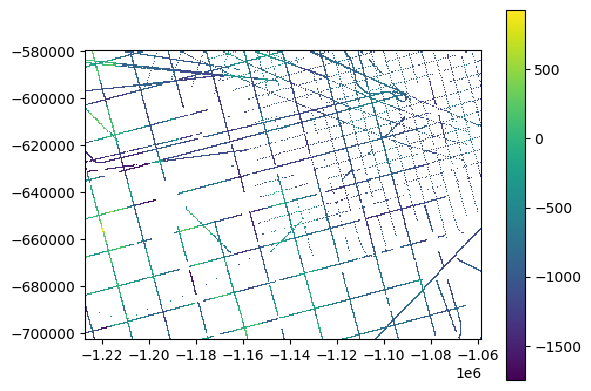

In [6]:
plt.pcolormesh(xx,yy,test_area1['surface'].values.reshape(xx.shape) - radar_thickness)
plt.colorbar()
plt.axis('scaled')

test_area1['radar_bed'] = test_area1['surface'] - np.flipud(radar_thickness)

In [7]:
test_area1['radar_bed'] = test_area1['surface'] - np.flipud(radar_thickness)
test_area1

<xarray.Dataset> Size: 2MB
Dimensions:    (y: 246, x: 338)
Coordinates:
  * y          (y) int32 984B -579500 -580000 -580500 ... -701500 -702000
  * x          (x) int32 1kB -1227000 -1226500 -1226000 ... -1059000 -1058500
Data variables:
    mapping    |S1 1B ...
    mask       (y, x) int8 83kB ...
    firn       (y, x) float32 333kB ...
    surface    (y, x) float32 333kB 1.583e+03 1.586e+03 ... 1.645e+03 1.644e+03
    thickness  (y, x) float32 333kB ...
    bed        (y, x) float32 333kB ...
    errbed     (y, x) float32 333kB ...
    source     (y, x) int8 83kB ...
    dataid     (y, x) int8 83kB ...
    geoid      (y, x) int16 166kB ...
    radar_bed  (y, x) float32 333kB nan nan nan nan nan ... nan nan nan -925.6
Attributes: (12/17)
    Conventions:                 CF-1.7
    Title:                       BedMachine Antarctica
    Author:                      Mathieu Morlighem
    version:                     03-Jun-2022 (v3.4)
    nx:                          13333.0
    ny:                          13333.0
    ...                          ...
    ymax:                        3333000
    spacing:                     500
    no_data:                     -9999.0
    license:                     No restrictions on access or use
    Data_citation:               Morlighem M. et al., (2019), Deep glacial tr...
    Notes:                       Data processed at the Department of Earth Sy...

In [8]:
df = test_area1.to_dataframe().reset_index()
df.head() 

# Grid data
res = 1000  # resolution
df_grid, grid_matrix, rows, cols = gs.Gridding.grid_data(df, 'x', 'y', 'radar_bed', res) # grid data
df_grid = df_grid[df_grid["Z"].isnull() == False]  # remove coordinates with NaNs
df_grid = df_grid.rename(columns = {"Z": "Bed"}) # rename column for consistency

# normal score transformation
data = df_grid['Bed'].values.reshape(-1,1)
nst_trans = QuantileTransformer(n_quantiles=100, output_distribution="normal").fit(data)
df_grid['Nbed'] = nst_trans.transform(data) 

# compute experimental (isotropic) variogram
coords = df_grid[['X','Y']].values
values = df_grid['Nbed']

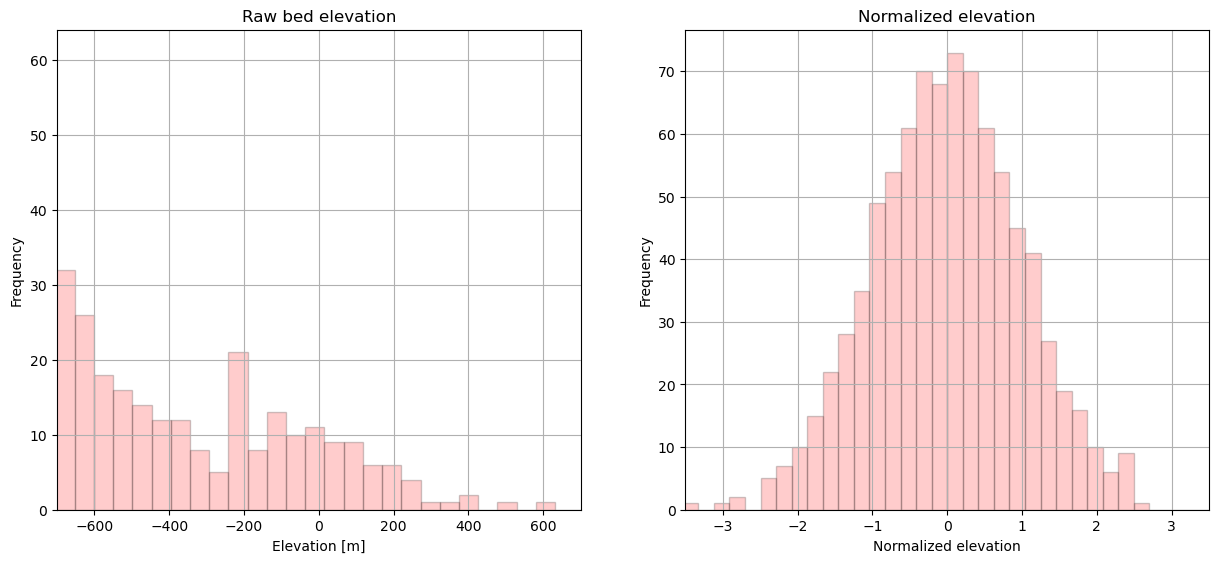

In [9]:
# plot original bed histogram
plt.subplot(121)
plt.hist(df_grid['Bed'], facecolor='red', bins=50, alpha=0.2, edgecolor='black')
plt.xlim([-700,700]); 
plt.xlabel('Elevation [m]'); plt.ylabel('Frequency'); plt.title('Raw bed elevation')
plt.grid(True)

# plot normal score bed histogram (with weights)
plt.subplot(122)
plt.hist(df_grid['Nbed'], facecolor='red', bins=50, alpha=0.2, edgecolor='black')
plt.xlim([-3.5,3.5]); 
plt.xlabel('Normalized elevation'); plt.ylabel('Frequency'); plt.title('Normalized elevation')
plt.grid(True)
plt.subplots_adjust(left=0.0, bottom=0.0, right=1.8, top=1.0, wspace=0.2, hspace=0.3)
plt.show()

In [10]:
# Compute experimental (isotropic) variogram
maxlag = 80000 # maximum range distance
n_lags = 50 #num of bins

V1 = skg.Variogram(coords, values, bin_func = "even", n_lags = n_lags, 
                   maxlag = maxlag, normalize=False)
V1.model = 'exponential' # use exponential variogram model
V1.parameters
print(f'exp: {V1.parameters}')

V2 = skg.Variogram(coords, values, bin_func = "even", n_lags = n_lags, 
                   maxlag = maxlag, normalize=False)
V2.model = 'matern'
print(f'matern: {V2.parameters}')

# evaluate models
xi =np.linspace(0, V1.bins[-1], 100) 

y_exp = models.exponential(xi, *V1.parameters)
y_matern = models.matern(xi, *V2.parameters)

exp: [76661.90000936076, 1.1539671696402296, 0]
matern: [79999.99999998644, 1.1726624537183832, 0.38210008192785433, 0]


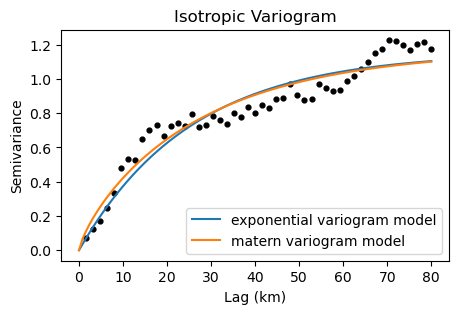

In [11]:
# Plot
plt.figure(figsize=(5,3))
plt.scatter(V1.bins/1000, V1.experimental, s=12, c='k')
plt.plot(xi/1000, y_exp, label='exponential variogram model')
plt.plot(xi/1000, y_matern, label='matern variogram model')
plt.title('Isotropic Variogram')
plt.xlabel('Lag (km)'); plt.ylabel('Semivariance')
plt.legend()

plt.show()

In [12]:
#correlation for ice surface and radar bed
#radar bed data is already gridded
#now gridding ice surface

res = 1000  # resolution
df_surf, grid_matrix_surf, rows, cols = gs.Gridding.grid_data(df, 'x', 'y', 'surface', res) # grid data
df_surf = df_surf[df_surf["Z"].isnull() == False]  # remove coordinates with NaNs
df_surf = df_surf.rename(columns = {"Z": "Surface"}) # rename column for consistency

# normal score transformation
data_surf = df_surf['Surface'].values.reshape(-1,1)
nst_trans_surf = QuantileTransformer(n_quantiles=100, output_distribution="normal").fit(data_surf)
df_surf['Nsurface'] = nst_trans_surf.transform(data_surf) 

# compute experimental (isotropic) variogram
coords_surf = df_surf[['X','Y']].values
values_surf = df_surf['Nsurface']

In [13]:
# find co-located secondary data (this may take a few minutes)
df_colocated_surf = gs.NearestNeighbor.find_colocated(df_grid, 'X', 'Y', 'Nbed', df_surf, 'X', 'Y', 'Nsurface')

In [14]:
# compute correlation coefficient
rho12 = np.corrcoef(df_grid['Nbed'],df_colocated_surf['colocated'])
corrcoef = rho12[0,1]
print('Correlation coefficient between bed and surface: ' + str(corrcoef))

Correlation coefficient between bed and surface: 0.4057524468213197


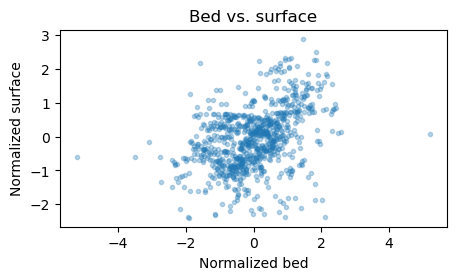

In [15]:
# scatter plot
plt.figure(figsize=(5,5))
im = plt.scatter(df_grid['Nbed'], df_colocated_surf['colocated'], alpha=0.3, marker='.')
plt.title('Bed vs. surface')
plt.xlabel('Normalized bed')
plt.ylabel('Normalized surface')
plt.axis('scaled')
plt.show()

In [16]:
#what ice thicknesses are they well correlated?
#surface v bed, ice thickness as color

In [17]:
# find co-located secondary data (this may take a few minutes)
df_colocated_surf = gs.NearestNeighbor.find_colocated(df_grid, 'X', 'Y', 'Bed', df_surf, 'X', 'Y', 'Surface')

In [18]:
# compute correlation coefficient
rho12 = np.corrcoef(df_grid['Bed'],df_colocated_surf['colocated'])
corrcoef = rho12[0,1]
print('Correlation coefficient between bed and surface: ' + str(corrcoef))

Correlation coefficient between bed and surface: 0.4579819171103714


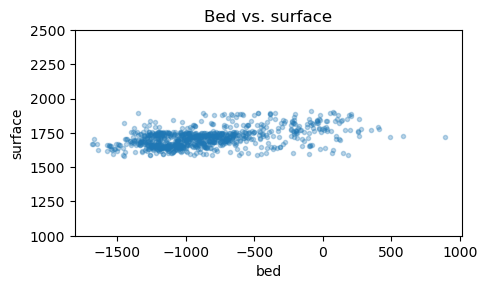

In [19]:
# scatter plot
plt.figure(figsize=(5,5))
im = plt.scatter(df_grid['Bed'], df_colocated_surf['colocated'], alpha=0.3, marker='.')
plt.title('Bed vs. surface')
plt.xlabel('bed')
plt.ylabel('surface')
plt.axis('scaled')
plt.ylim(1000, 2500)
plt.show()

In [20]:
# rebuild BED grid explicitly so grid_matrix can't be the surface grid
df_bed, grid_matrix_bed, rows_bed, cols_bed = gs.Gridding.grid_data(df, 'x', 'y', 'radar_bed', res)

smooth_radius = 50000 # smoothing radius 50km
trend_rbf = gs.rbf_trend(grid_matrix_bed, smooth_radius, res)

diff = grid_matrix_bed - trend_rbf.T
diff = np.flipud(diff)

ny, nx = diff.shape
diff_array = np.reshape(diff, [ny*nx])
diff_array = diff_array[~np.isnan(diff_array)]

df_grid['Residual'] = diff_array

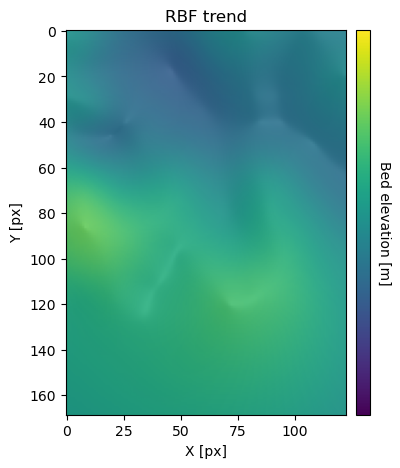

In [21]:
# Shade from the northeast, with the sun 45 degrees from horizontal
ls = LightSource(azdeg=45, altdeg=45)

# leaving the dx and dy as 1 means a vertical exageration equal to dx/dy
hillshade = ls.hillshade(trend_rbf, vert_exag=1, dx=1, dy=1, fraction=1.0)

fig, ax = plt.subplots(figsize=(5, 5))
im = ax.imshow(trend_rbf, vmin=-2000, vmax=500, cmap="viridis")
ax.imshow(hillshade, cmap='gray', alpha=0.1)
ax.set_title('RBF trend')
ax.set_xlabel('X [px]'); ax.set_ylabel('Y [px]')
divider = make_axes_locatable(ax)
cax = divider.append_axes('right', size='5%', pad=0.1)
cbar = plt.colorbar(im, ticks=np.linspace(1500, 2500, 11), cax=cax)
cbar.set_label("Bed elevation [m]", rotation=270, labelpad=15)
ax.axis('scaled')
plt.show()

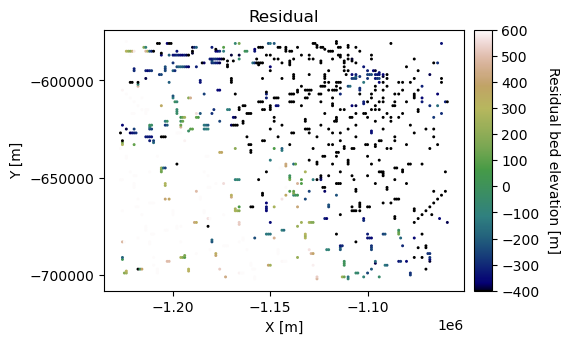

In [22]:
# plot residual 
fig = plt.figure(figsize = (5,5))
ax = plt.gca()
im = ax.scatter(df_grid['X'], df_grid['Y'], c=df_grid['Residual'], vmin=-400, vmax=600, 
                     marker='.', s=5, cmap='gist_earth')
plt.title('Residual')
plt.xlabel('X [m]'); plt.ylabel('Y [m]')
plt.locator_params(nbins=5)
plt.axis('scaled')

# make colorbar
divider = make_axes_locatable(ax)
cax = divider.append_axes('right', size='5%', pad=0.1)
cbar = plt.colorbar(im, ticks=np.linspace(-400, 600, 11), cax=cax)
cbar.set_label("Residual bed elevation [m]", rotation=270, labelpad=15)
plt.show()

In [23]:
# define coordinate grid
xmin = np.min(df_grid['X']); xmax = np.max(df_grid['X'])     # min and max x values
ymin = np.min(df_grid['Y']); ymax = np.max(df_grid['Y'])     # min and max y values

Pred_grid_xy = gs.Gridding.prediction_grid(xmin, xmax, ymin, ymax, res)


In [24]:
# normal score transform of the residual
data_r = df_grid['Residual'].values.reshape(-1,1)
nst_trans_r = QuantileTransformer(n_quantiles=100, output_distribution="normal").fit(data_r)
df_grid['Nresidual'] = nst_trans_r.transform(data_r)

# variogram of the normalized residual
coords = df_grid[['X','Y']].values
values = df_grid['Nresidual']

V3 = skg.Variogram(coords, values, bin_func="even", n_lags=50,
                   maxlag=80000, normalize=False)
V3.model = 'matern'
print(V3.parameters)

[79999.99999999558, 1.0560596857733258, 0.7509944989835331, 0]


In [25]:
# set parameters
azimuth = 0
nugget = V3.parameters[-1] 

# the major and minor ranges are the same in this example because it is isotropic
major_range = V3.parameters[0]
minor_range = V3.parameters[0]
sill = V3.parameters[1]
smoothness = V3.parameters[2] 
vtype = 'matern'

# save variogram parameters as a list
vario = [azimuth, nugget, major_range, minor_range, sill, vtype, smoothness]

k = 10         # number of neighboring data points used to estimate a given point
rad = 30000     # 30 km search radius

# est_SK is the estimate and var_SK is the variance
est_SK, var_SK = gs.Interpolation.skrige(Pred_grid_xy, df_grid, 'X', 'Y', 'Nresidual', k, vario, rad)

100%|██████████| 20787/20787 [10:29<00:00, 33.01it/s]


In [30]:
# reverse normal score transformation
est = est_SK.reshape(-1,1)
spred_trans = nst_trans_r.inverse_transform(est)

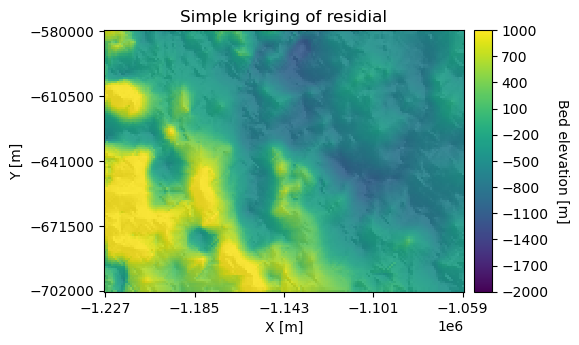

In [31]:
# make hillshade for visualizing
vmin = -2000; vmax = 1000
x_mat = Pred_grid_xy[:,0].reshape((rows, cols))
y_mat = Pred_grid_xy[:,1].reshape((rows, cols))
mat = spred_trans.reshape((rows, cols))
xmin = Pred_grid_xy[:,0].min(); xmax = Pred_grid_xy[:,0].max()
ymin = Pred_grid_xy[:,1].min(); ymax = Pred_grid_xy[:,1].max()
    
cmap=plt.get_cmap('gist_earth')
fig, ax = plt.subplots(1, figsize=(5,5))
im = ax.pcolormesh(x_mat, y_mat, mat, vmin=vmin, vmax=vmax, cmap="viridis")
    
# Shade from the northeast, with the sun 45 degrees from horizontal
ls = LightSource(azdeg=45, altdeg=45)
        
# leaving the dx and dy as 1 means a vertical exageration equal to dx/dy
hillshade = ls.hillshade(mat, vert_exag=1, dx=1, dy=1, fraction=1.0)
plt.pcolormesh(x_mat, y_mat, hillshade, cmap='gray', alpha=0.1)
plt.title('Simple kriging of residial')
plt.xlabel('X [m]'); plt.ylabel('Y [m]')
plt.xticks(np.linspace(xmin, xmax, 5))
plt.yticks(np.linspace(ymin, ymax, 5))

# make colorbar
divider = make_axes_locatable(ax)
cax = divider.append_axes('right', size='5%', pad=0.1)
cbar = plt.colorbar(im, ticks=np.linspace(-2000, 1000, 11), cax=cax)
cbar.set_label("Bed elevation [m]", rotation=270, labelpad=15)
ax.axis('scaled')
plt.show()

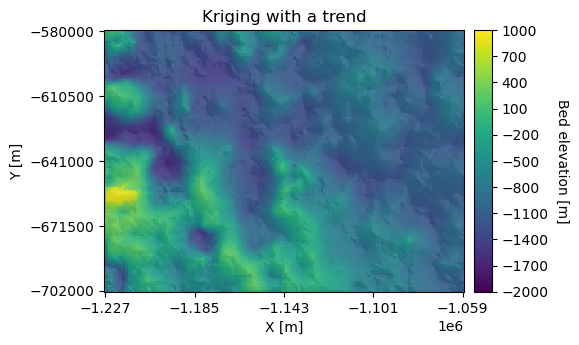

In [32]:

# add trend to kriging result
sk_total = mat + trend_rbf.T
    
cmap=plt.get_cmap('gist_earth')
fig, ax = plt.subplots(1, figsize=(5,5))
im = ax.pcolormesh(x_mat, y_mat, sk_total, vmin=-2000, vmax=1000, cmap="viridis")
    
# Shade from the northeast, with the sun 45 degrees from horizontal
ls = LightSource(azdeg=45, altdeg=45)
        
# leaving the dx and dy as 1 means a vertical exageration equal to dx/dy
hillshade = ls.hillshade(mat, vert_exag=1, dx=1, dy=1, fraction=1.0)
plt.pcolormesh(x_mat, y_mat, hillshade, cmap='gray', alpha=0.1)
plt.title('Kriging with a trend')
plt.xlabel('X [m]'); plt.ylabel('Y [m]')
plt.xticks(np.linspace(xmin, xmax, 5))
plt.yticks(np.linspace(ymin, ymax, 5))

# make colorbar
divider = make_axes_locatable(ax)
cax = divider.append_axes('right', size='5%', pad=0.1)
cbar = plt.colorbar(im, ticks=np.linspace(-2000, 1000, 11), cax=cax)
cbar.set_label("Bed elevation [m]", rotation=270, labelpad=15)
ax.axis('scaled')
plt.show()

In [33]:
#SGS
rng = np.random.default_rng(seed=0)
sim = gs.Interpolation.skrige_sgs(Pred_grid_xy, df_grid, 'X', 'Y', 'Nresidual', k, vario, rad, seed=rng) 

100%|██████████| 20787/20787 [11:42<00:00, 29.58it/s]


In [34]:

# reverse normal score transformation
sim1 = sim.reshape(-1,1)
sim_trans = nst_trans_r.inverse_transform(sim1)

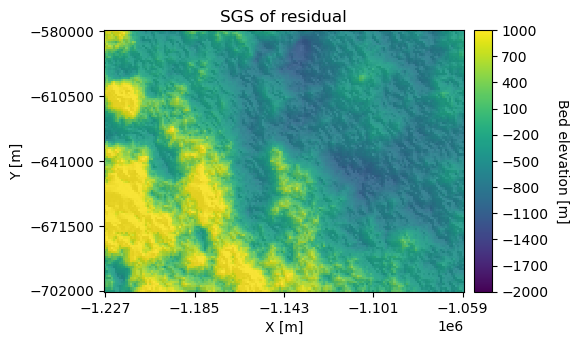

In [35]:
# make hillshade for visualizing
mat = sim_trans.reshape((rows, cols))

cmap=plt.get_cmap('gist_earth')
fig, ax = plt.subplots(1, figsize=(5,5))
im = ax.pcolormesh(x_mat, y_mat, mat, vmin=vmin, vmax=vmax, cmap="viridis")
    
# Shade from the northeast, with the sun 45 degrees from horizontal
ls = LightSource(azdeg=45, altdeg=45)
        
# leaving the dx and dy as 1 means a vertical exageration equal to dx/dy
hillshade = ls.hillshade(mat, vert_exag=1, dx=1, dy=1, fraction=1.0)
plt.pcolormesh(x_mat, y_mat, hillshade, cmap='gray', alpha=0.1)
plt.title('SGS of residual')
plt.xlabel('X [m]'); plt.ylabel('Y [m]')
plt.xticks(np.linspace(xmin, xmax, 5))
plt.yticks(np.linspace(ymin, ymax, 5))

# make colorbar
divider = make_axes_locatable(ax)
cax = divider.append_axes('right', size='5%', pad=0.1)
cbar = plt.colorbar(im, ticks=np.linspace(-2000, 1000, 11), cax=cax)
cbar.set_label("Bed elevation [m]", rotation=270, labelpad=15)
ax.axis('scaled')
plt.show()

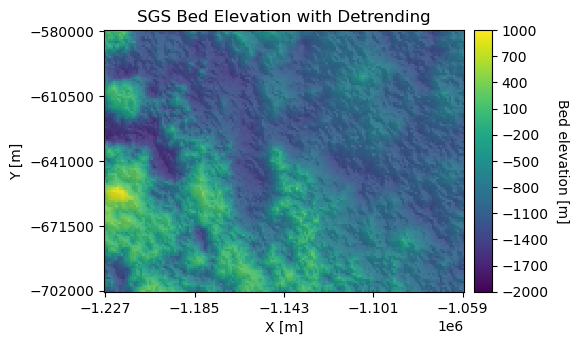

In [36]:
# add trend
sgs_total = mat + trend_rbf.T

# make hillshade for visualizing
cmap=plt.get_cmap('gist_earth')
fig, ax = plt.subplots(1, figsize=(5,5))
im = ax.pcolormesh(x_mat, y_mat, sgs_total, vmin=-2000, vmax=1000, cmap="viridis")
    
# Shade from the northeast, with the sun 45 degrees from horizontal
ls = LightSource(azdeg=45, altdeg=45)
        
# leaving the dx and dy as 1 means a vertical exageration equal to dx/dy
hillshade = ls.hillshade(mat, vert_exag=1, dx=1, dy=1, fraction=1.0)
plt.pcolormesh(x_mat, y_mat, hillshade, cmap='gray', alpha=0.1)
plt.title('SGS Bed Elevation with Detrending')
plt.xlabel('X [m]'); plt.ylabel('Y [m]')
plt.xticks(np.linspace(xmin, xmax, 5))
plt.yticks(np.linspace(ymin, ymax, 5))

# make colorbar
divider = make_axes_locatable(ax)
cax = divider.append_axes('right', size='5%', pad=0.1)
cbar = plt.colorbar(im, ticks=np.linspace(-2000, 1000, 11), cax=cax)
cbar.set_label("Bed elevation [m]", rotation=270, labelpad=15)
ax.axis('scaled')
plt.show()